# Gradient Domain Editing

Notebook ghép đối tượng từ **ảnh nguồn** vào **ảnh nền** và so sánh bốn phương pháp: **dán trực tiếp → feather (alpha) → Laplacian pyramid → Poisson blending (import gradients)**. Cả bốn phương pháp dùng cùng ảnh nền, cùng mask và cùng vị trí đặt; chỉ khác cách xử lý vùng biên.

**Đầu ra quan sát được:** ảnh nguồn và nền; mask đối tượng; ảnh nguồn sau khi đặt lên canvas nền; kết quả của từng phương pháp; lưới so sánh; ảnh phóng to vùng biên.

Với Poisson blending, mỗi pixel trong mask là một ẩn của hệ phương trình tuyến tính thưa: gradient của kết quả phải khớp với gradient của ảnh nguồn, còn giá trị ngoài mask giữ nguyên làm điều kiện biên (hàm mục tiêu rời rạc trong slide Chap05 tr.19).

Cần `opencv-python`, `numpy`, `scipy` và `IPython` (xem `requirements.txt`).

## 1. Dữ liệu và cấu hình

Cặp ảnh mẫu là `background.jpg` (nền) và `anhnhanvat.jpg` (nhân vật, 1200×675). Với cặp mẫu, mask lấy từ **đa giác vẽ tay** có sẵn (`MASK_POINTS` trừ phần lỗ `MASK_HOLE`). Mọi tham số nằm trong `CONFIG`:

- `mask`: đường dẫn mask cùng kích thước ảnh nguồn; `rect`: khung `(x, y, w, h)` cho GrabCut. Để cả hai là `None` thì cặp mẫu dùng đa giác có sẵn. Với ảnh nguồn khác, cần đặt một trong hai.
- `scale`: hệ số thu phóng ảnh nguồn (mặc định 1.0 với ảnh mẫu, 0.35 với ảnh khác).
- `pos`: góc trên trái của ảnh nguồn sau khi scale, `None` để tự chọn (ảnh mẫu lệch trái, ảnh khác ở giữa nền).
- `save_dir`: thư mục lưu ảnh kết quả; `None` để chỉ hiển thị trong notebook.

Bản `.py` gốc còn chế độ click đa giác bằng cửa sổ OpenCV; chế độ này cần cửa sổ GUI nên không có trong notebook.

OpenCV: 5.0.0 | NumPy: 2.4.6


**Ảnh nền — background.jpg (1440×900)**

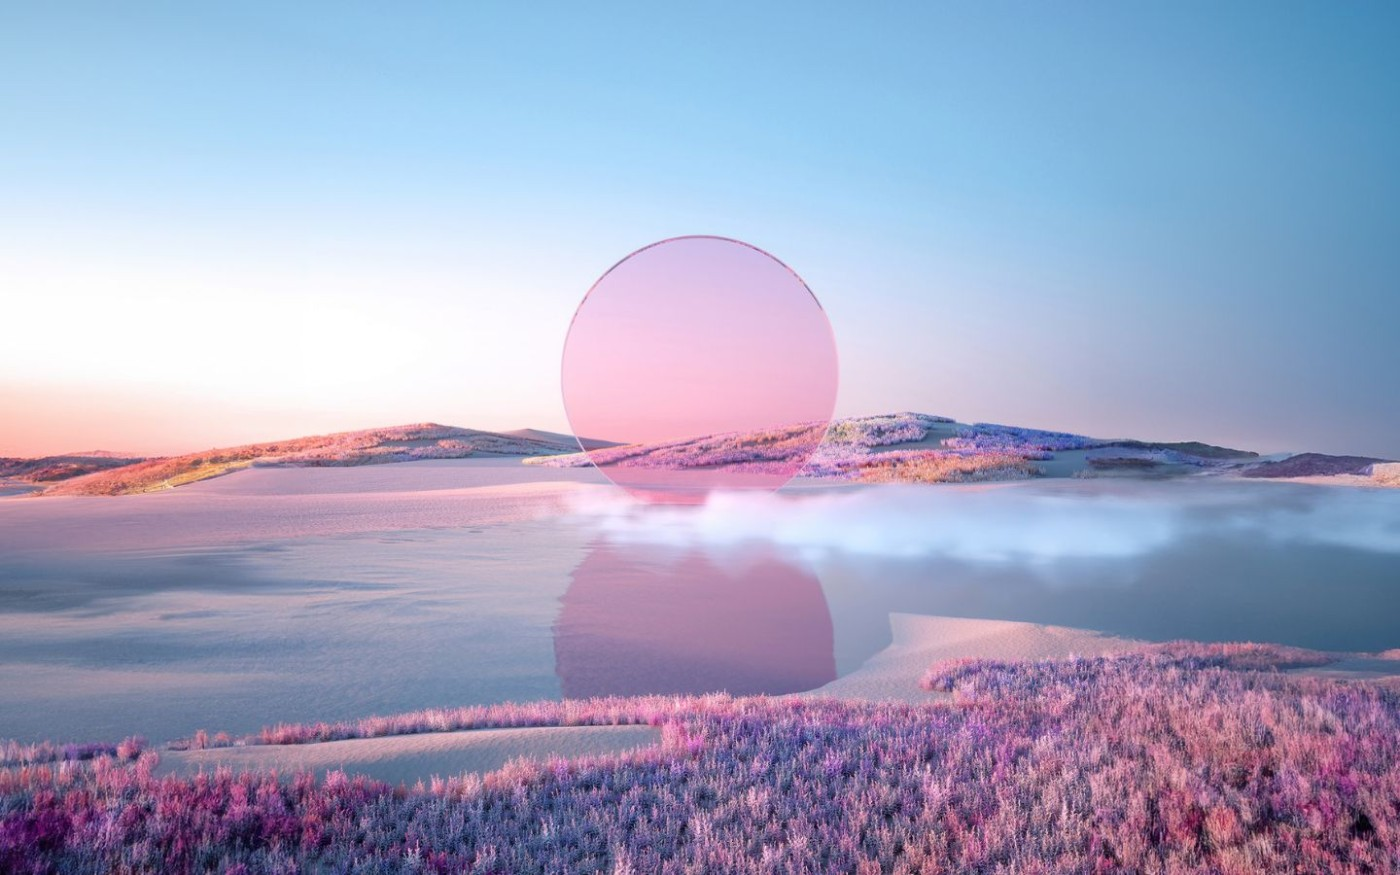

**Ảnh nguồn — anhnhanvat.jpg (1200×675)**

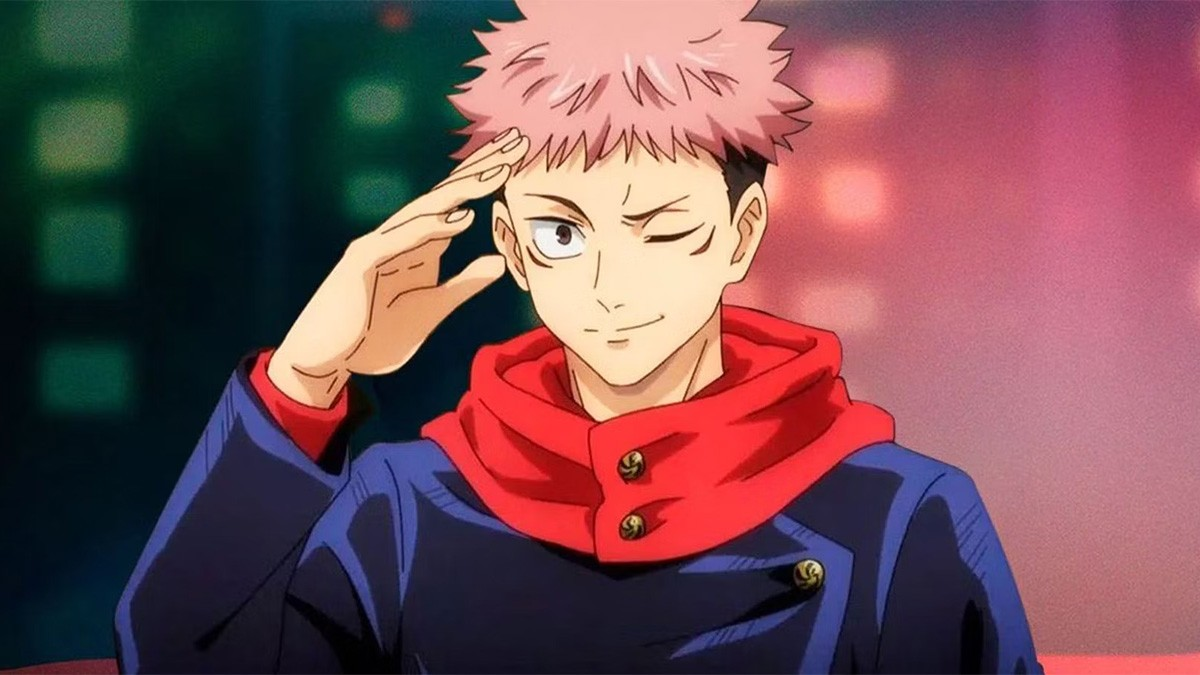

In [1]:
from pathlib import Path

import cv2
import numpy as np
import scipy.sparse as sparse
from IPython.display import Image as NotebookImage, Markdown, display
from scipy.sparse.linalg import factorized

print("OpenCV:", cv2.__version__, "| NumPy:", np.__version__)

ROOT = Path.cwd()
BACKGROUND = ROOT / "background.jpg"
SOURCE = ROOT / "anhnhanvat.jpg"
CONFIG = {
    "mask": None,
    "rect": None,
    "pos": None,
    "scale": 1.0 if SOURCE.name == "anhnhanvat.jpg" else 0.35,
    "save_dir": None,
}

MASK_SIZE = (1200, 675)
MASK_POINTS = [
    (515, 0), (750, 0), (747, 9), (738, 20), (781, 25), (769, 42), (795, 51), (782, 67),
    (805, 82), (792, 93), (814, 106), (793, 115), (808, 126), (786, 131), (791, 144), (774, 146),
    (777, 164), (764, 160), (763, 191), (771, 194), (771, 218), (764, 246), (749, 276), (725, 296),
    (724, 305), (754, 309), (791, 322), (820, 326), (835, 339), (841, 364), (854, 377), (863, 403),
    (887, 416), (896, 440), (927, 451), (952, 468), (973, 493), (993, 528), (1008, 562), (1026, 611),
    (1041, 650), (1045, 674), (118, 674), (116, 643), (113, 616), (122, 583), (141, 540), (160, 500),
    (183, 457), (204, 415), (225, 376), (239, 357), (256, 351), (271, 346), (292, 315), (318, 281),
    (344, 253), (365, 235), (393, 214), (423, 193), (452, 169), (480, 150), (463, 140), (451, 127),
    (469, 119), (448, 98), (478, 91), (457, 80), (480, 67), (465, 54), (490, 46), (474, 32),
    (500, 29), (487, 19), (525, 20),
]
MASK_HOLE = [
    (493, 204), (479, 208), (471, 218), (462, 229), (449, 238), (441, 243), (439, 257), (437, 270),
    (437, 283), (453, 276), (470, 266), (483, 258), (495, 257), (503, 261), (505, 268), (502, 277),
    (488, 287), (470, 301), (449, 317), (431, 334), (412, 353), (393, 368), (377, 374), (356, 377),
    (339, 374), (343, 393), (348, 414), (344, 439), (365, 439), (395, 442), (422, 447), (420, 440),
    (421, 429), (439, 419), (458, 410), (466, 396), (469, 379), (470, 361), (477, 350), (496, 344),
    (521, 337), (542, 326), (534, 314), (528, 299), (524, 287), (514, 275), (505, 257), (499, 244),
    (495, 229), (493, 213),
]


def read_image(path, flags=cv2.IMREAD_COLOR):
    """Đọc ảnh từ file."""
    image = cv2.imdecode(np.fromfile(path, np.uint8), flags) if path.is_file() else None
    if image is None:
        raise ValueError(f"Không đọc được ảnh: {path}")
    return image


def write_image(path, image):
    """Ghi ảnh ra file."""
    cv2.imencode(path.suffix or ".png", image)[1].tofile(path)


def show_image(title, image, max_width=1400):
    # Hiển thị JPEG gọn để output nằm ngay trong file notebook.
    display(Markdown(f"**{title}**"))
    scale = min(1.0, max_width / image.shape[1])
    preview = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA) if scale < 1 else image
    encoded = cv2.imencode(".jpg", preview, [cv2.IMWRITE_JPEG_QUALITY, 90])[1]
    display(NotebookImage(data=encoded.tobytes()))


def make_grid(tiles, cols, gap=6):
    """Xếp các ảnh thành lưới."""
    h, w = tiles[0].shape[:2]
    rows = (len(tiles) + cols - 1) // cols
    grid = np.full((rows * (h + gap) - gap, cols * (w + gap) - gap, 3), 255, np.uint8)
    for i, tile in enumerate(tiles):
        r, c = divmod(i, cols)
        y, x = r * (h + gap), c * (w + gap)
        grid[y:y + h, x:x + w] = tile
    return grid


def labeled(image, text):
    """Gắn nhãn lên góc trên ảnh."""
    tile = image.copy()
    font = cv2.FONT_HERSHEY_SIMPLEX
    scale = max(0.5, tile.shape[1] / 900)
    thick = max(1, round(2 * scale))
    (w, h), base = cv2.getTextSize(text, font, scale, thick)
    cv2.rectangle(tile, (0, 0), (w + 12, h + base + 12), (0, 0, 0), -1)
    cv2.putText(tile, text, (6, h + 6), font, scale, (255, 255, 255), thick, cv2.LINE_AA)
    return tile


target = read_image(BACKGROUND)
original_source = read_image(SOURCE)
show_image(f"Ảnh nền — {BACKGROUND.name} ({target.shape[1]}×{target.shape[0]})", target)
show_image(f"Ảnh nguồn — {SOURCE.name} ({original_source.shape[1]}×{original_source.shape[0]})", original_source)

## 2. Tạo mask

Mask xác định pixel nào của ảnh nguồn được ghép sang nền. Có ba nguồn mask, theo thứ tự ưu tiên: file `CONFIG["mask"]`; đa giác có sẵn cho cặp ảnh mẫu; GrabCut từ khung chữ nhật `CONFIG["rect"]` (5 vòng lặp, sau đó giãn nhẹ mask 3×3 để không cắt sát đối tượng). Mask luôn được nhị phân hóa về 0/255. Hình dưới vẽ đường biên mask lên ảnh nguồn để kiểm tra mask có bám đúng đối tượng.

**Ảnh nguồn + đường biên mask**

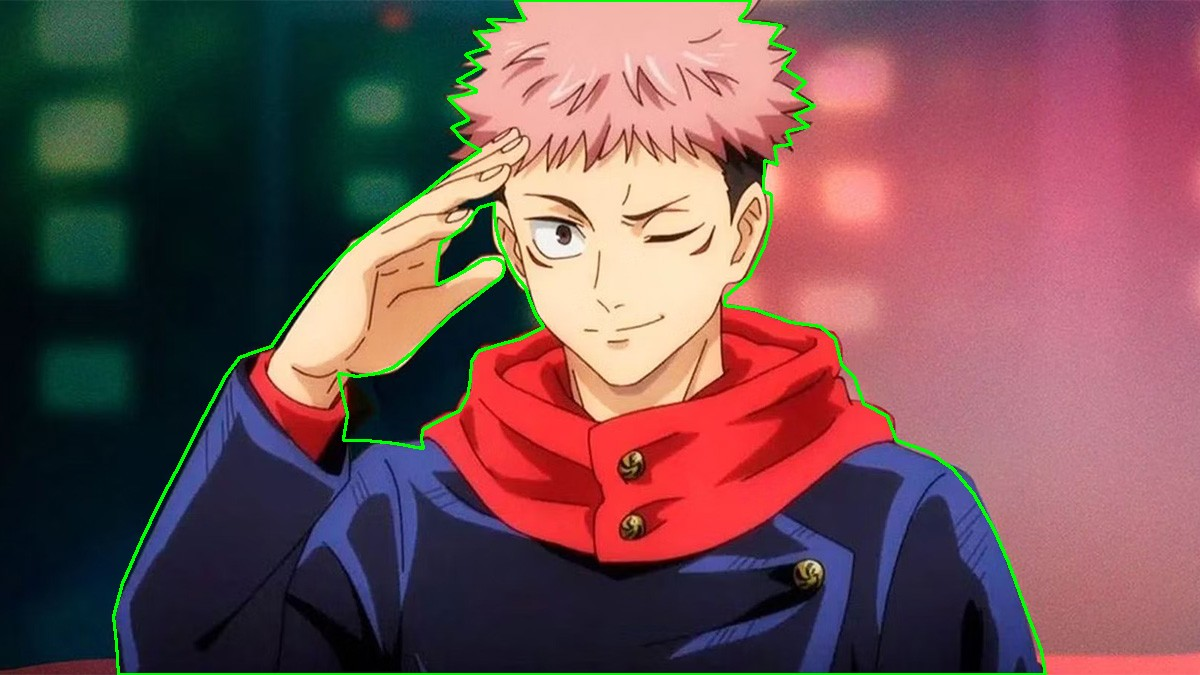

**Mask (372084 pixel đối tượng)**

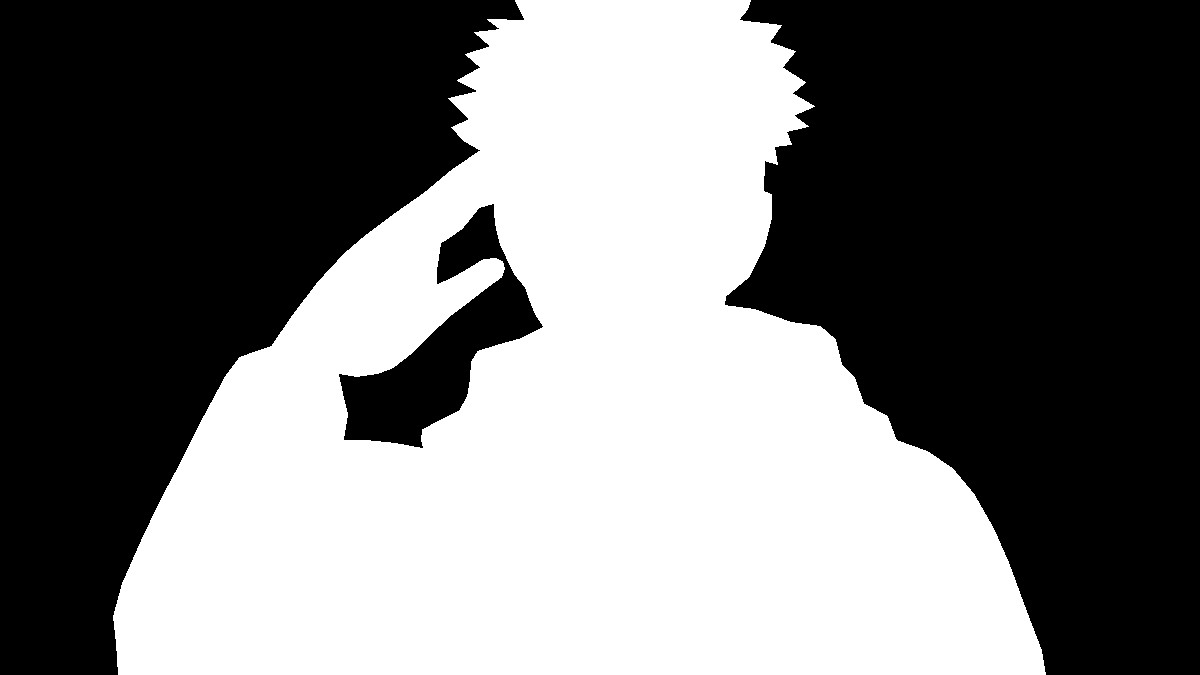

In [2]:
def binarize(mask):
    """Nhị phân hóa mask về 0/255."""
    return np.where(mask > 127, 255, 0).astype(np.uint8)


def grabcut_mask(source, rect):
    """Tạo mask bằng GrabCut từ khung chữ nhật quanh đối tượng."""
    x, y, w, h = rect
    sh, sw = source.shape[:2]
    if w <= 0 or h <= 0 or x < 0 or y < 0 or x + w > sw or y + h > sh or w * h == sw * sh:
        raise ValueError("Khung GrabCut phải nằm trong ảnh và chừa lại một phần nền bên ngoài.")
    gc = np.zeros((sh, sw), np.uint8)
    bgd, fgd = np.zeros((1, 65)), np.zeros((1, 65))
    cv2.grabCut(source, gc, tuple(rect), bgd, fgd, 5, cv2.GC_INIT_WITH_RECT)
    mask = np.where((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    return cv2.dilate(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))


def polygon_mask(source):
    """Tạo mask nhân vật từ đa giác vẽ tay có sẵn."""
    if source.shape[1::-1] != MASK_SIZE:
        raise ValueError("Kích thước ảnh nguồn không khớp mask có sẵn.")
    mask = np.zeros(source.shape[:2], np.uint8)
    cv2.fillPoly(mask, [np.int32(MASK_POINTS)], 255)
    cv2.fillPoly(mask, [np.int32(MASK_HOLE)], 0)
    return mask


def load_mask(config, source, use_preset):
    """Tạo mask cho ảnh nguồn."""
    if config["mask"]:
        mask = read_image(Path(config["mask"]), cv2.IMREAD_GRAYSCALE)
        if mask.shape != source.shape[:2]:
            raise ValueError("Mask phải cùng kích thước với ảnh nguồn gốc.")
    elif use_preset:
        mask = polygon_mask(source)
    elif config["rect"]:
        mask = grabcut_mask(source, config["rect"])
    else:
        raise ValueError("Ảnh nguồn khác ảnh mẫu: cần đặt CONFIG['mask'] hoặc CONFIG['rect'].")
    mask = binarize(mask)
    if not mask.any():
        raise ValueError("Mask không chứa đối tượng.")
    return mask


use_preset = SOURCE.name == "anhnhanvat.jpg" and not (CONFIG["mask"] or CONFIG["rect"])
source_mask = load_mask(CONFIG, original_source, use_preset)

source_view = original_source.copy()
contours, _ = cv2.findContours(source_mask, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(source_view, contours, -1, (0, 255, 0), 2)
show_image("Ảnh nguồn + đường biên mask", source_view)
show_image(f"Mask ({int((source_mask > 0).sum())} pixel đối tượng)", source_mask)

## 3. Đặt đối tượng lên canvas nền

Ảnh nguồn và mask được thu phóng theo `scale` (`INTER_AREA` khi thu nhỏ, `INTER_LINEAR` khi phóng to; mask luôn dùng `INTER_NEAREST` để giữ giá trị nhị phân), rồi đặt vào canvas cùng kích thước ảnh nền tại `pos`. Phần ảnh nguồn nằm ngoài canvas bị cắt. Ngoài vùng ảnh nguồn, canvas giữ nguyên ảnh nền, nên `src` và `target` chỉ khác nhau trong vùng ảnh nguồn.

Hàng pixel và cột pixel ngoài cùng của mask bị xóa về 0. Đây là điều kiện bắt buộc của Poisson: mỗi pixel trong mask cần đủ bốn láng giềng nằm trong ảnh, và láng giềng nằm ngoài mask cung cấp giá trị biên từ ảnh nền.

scale = 1.0 | ảnh nguồn sau scale: 1200×675 | góc trên trái: (-330, 225)


**Ảnh nguồn đã đặt lên canvas nền + mask**

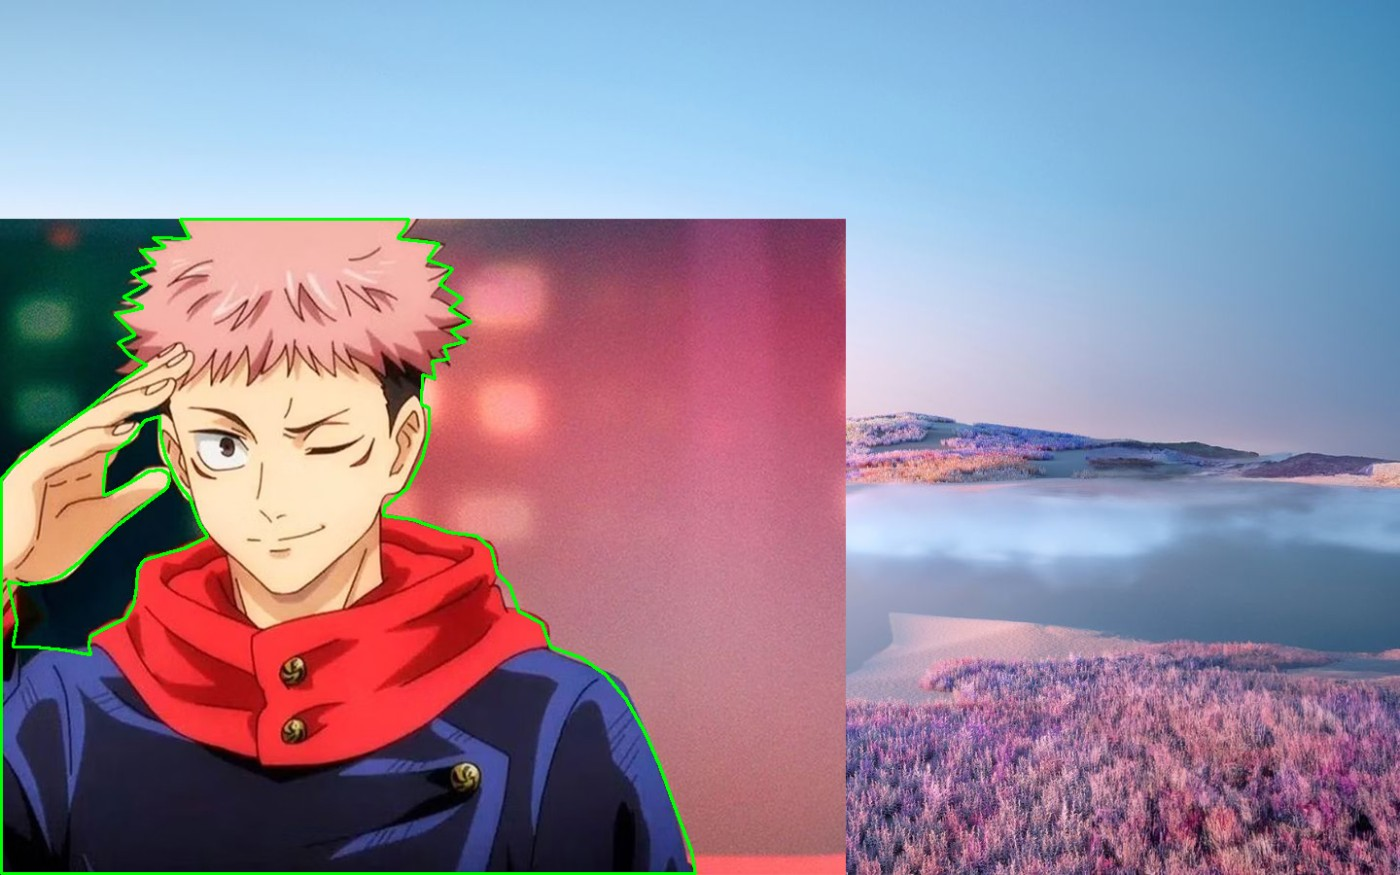

In [3]:
def resize_source(source, mask, scale):
    """Thu phóng ảnh nguồn và mask."""
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("scale phải là số hữu hạn > 0.")
    size = (round(source.shape[1] * scale), round(source.shape[0] * scale))
    if min(size) < 1:
        raise ValueError("scale quá nhỏ.")
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(source, size, interpolation=interp), cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST)


def choose_position(pos, source, mask, target, use_preset):
    """Chọn vị trí đặt ảnh nguồn lên ảnh nền."""
    if pos:
        return tuple(pos)
    if use_preset:
        return (-round(0.275 * source.shape[1]), target.shape[0] - source.shape[0])
    x, y, w, h = cv2.boundingRect(mask)
    return (target.shape[1] // 2 - x - w // 2, target.shape[0] // 2 - y - h // 2)


def place_on_target(source, mask, target, top_left):
    """Đặt ảnh nguồn và mask lên khung ảnh nền."""
    th, tw = target.shape[:2]
    sh, sw = source.shape[:2]
    x0, y0 = top_left
    tx0, ty0 = max(x0, 0), max(y0, 0)
    tx1, ty1 = min(x0 + sw, tw), min(y0 + sh, th)
    if tx0 >= tx1 or ty0 >= ty1:
        raise ValueError("Ảnh nguồn nằm hoàn toàn ngoài ảnh nền.")

    src = target.copy()
    msk = np.zeros((th, tw), np.uint8)
    src[ty0:ty1, tx0:tx1] = source[ty0 - y0:ty1 - y0, tx0 - x0:tx1 - x0]
    msk[ty0:ty1, tx0:tx1] = mask[ty0 - y0:ty1 - y0, tx0 - x0:tx1 - x0]
    msk = binarize(msk)
    msk[[0, -1], :] = msk[:, [0, -1]] = 0
    if not msk.any():
        raise ValueError("Mask rỗng sau khi đặt lên nền; kiểm tra mask, pos và scale.")
    return src, msk


source, mask = resize_source(original_source, source_mask, CONFIG["scale"])
top_left = choose_position(CONFIG["pos"], source, mask, target, use_preset)
src, msk = place_on_target(source, mask, target, top_left)
print(f"scale = {CONFIG['scale']} | ảnh nguồn sau scale: {source.shape[1]}×{source.shape[0]} | góc trên trái: {top_left}")

placed_view = src.copy()
contours, _ = cv2.findContours(msk, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(placed_view, contours, -1, (0, 255, 0), 2)
show_image("Ảnh nguồn đã đặt lên canvas nền + mask", placed_view)

## 4. Các phương pháp ghép

Ba phương pháp đầu không giải phương trình; chúng chỉ trộn giá trị pixel:

- **Direct paste:** thay pixel trong mask bằng pixel nguồn. Biên mask lộ rõ vì không có xử lý màu hay độ sáng.
- **Feather (alpha):** alpha blending $f = \alpha g + (1-\alpha) t$ (Chap05 tr.8). Bản đồ $\alpha$ lấy từ mask: co lại bằng erosion rồi làm mờ Gaussian (`sigma = 5`), nên alpha không tràn ra ngoài mask. Kích thước kernel và `sigma` là lựa chọn của chương trình. Màu nguồn không được chỉnh nên vẫn có thể khác nền.
- **Laplacian pyramid:** trộn riêng từng dải tần số với mask đã giảm mẫu ở cùng mức (5 mức); slide chỉ nêu ý tưởng này (Chap05 tr.9–10), cách xây tháp bằng `pyrDown`/`pyrUp` là hiện thực của chương trình.

**Poisson blending (import gradients)** (Chap05 tr.19). Gọi $g$ là ảnh nguồn đã đặt lên canvas, $t$ là ảnh nền, $\Omega$ là vùng mask, $N_p$ là bốn láng giềng của $p$. Các pixel $f_p$ ($p \in \Omega$) là ẩn số của bài toán bình phương tối thiểu:

$$\hat f = \arg\min_f \sum_{\{p,q\}:\,p,q \in \Omega,\, q \in N_p} \big((f_p - f_q) - (g_p - g_q)\big)^2 + \sum_{p \in \Omega}\sum_{q \in N_p \setminus \Omega} \big((f_p - t_q) - (g_p - g_q)\big)^2$$

Số hạng đầu giữ gradient nguồn giữa hai pixel cùng trong mask; số hạng sau cố định giá trị nền $t_q$ tại biên. Đặt đạo hàm theo từng $f_p$ bằng 0 (bước do chương trình suy ra, không phải công thức ghi sẵn trong slide) cho hệ, với mask đã chừa biên canvas nên mỗi $p$ có đủ bốn láng giềng:

$$4 f_p - \sum_{q \in N_p \cap \Omega} f_q = \sum_{q \in N_p \setminus \Omega} t_q + \sum_{q \in N_p} (g_p - g_q)$$

Viết thành $M f = b$ với $M = 4I - \text{adjacency}$ (ma trận thưa; khác ma trận $A$ trong công thức bình phương tối thiểu tổng quát của slide) và một hệ cho từng kênh màu. $M$ được phân rã một lần bằng `factorized` rồi dùng cho cả ba kênh.

In [4]:
def direct_paste(target, source, mask):
    """Dán trực tiếp ảnh nguồn lên ảnh nền."""
    return np.where(mask[..., None] > 0, source, target)


def feather_blend(target, source, mask, sigma=5.0):
    """Ghép bằng alpha blending với biên mask làm mờ."""
    kernel = np.ones((int(4 * sigma) + 1,) * 2, np.uint8)
    alpha = cv2.erode(mask, kernel).astype(np.float64) / 255
    alpha = cv2.GaussianBlur(alpha, (0, 0), sigma) * (mask > 0)
    alpha = alpha[..., None]
    return (alpha * source + (1 - alpha) * target).astype(np.uint8)


def pyramid_blend(target, source, mask, levels=5):
    """Ghép bằng Laplacian pyramid."""
    ga = [source.astype(np.float32)]
    gb = [target.astype(np.float32)]
    gm = [cv2.merge([mask.astype(np.float32) / 255] * 3)]
    for _ in range(levels):
        ga.append(cv2.pyrDown(ga[-1]))
        gb.append(cv2.pyrDown(gb[-1]))
        gm.append(cv2.pyrDown(gm[-1]))

    blended = gm[-1] * ga[-1] + (1 - gm[-1]) * gb[-1]
    for i in reversed(range(levels)):
        size = ga[i].shape[1::-1]
        la = ga[i] - cv2.pyrUp(ga[i + 1], dstsize=size)
        lb = gb[i] - cv2.pyrUp(gb[i + 1], dstsize=size)
        blended = cv2.pyrUp(blended, dstsize=size) + gm[i] * la + (1 - gm[i]) * lb
    return np.clip(blended, 0, 255).astype(np.uint8)


def poisson_blend(target, source, mask):
    """Poisson blending (import gradients): giữ gradient nguồn, cố định nền ngoài mask."""
    if mask[[0, -1], :].any() or mask[:, [0, -1]].any():
        raise ValueError("Mask Poisson phải chừa biên ngoài canvas một pixel.")
    t = target.astype(np.float64)
    g = source.astype(np.float64)

    ys, xs = np.nonzero(mask)
    n = len(ys)
    if n == 0:
        return target.copy()
    index = np.full(mask.shape, -1)
    index[ys, xs] = np.arange(n)

    rows, cols = [], []
    b = np.zeros((n, 3))
    for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        qy, qx = ys + dy, xs + dx
        b += g[ys, xs] - g[qy, qx]

        q = index[qy, qx]
        inside = q >= 0
        rows.append(np.nonzero(inside)[0])
        cols.append(q[inside])
        # Láng giềng ngoài mask là điều kiện biên: lấy giá trị từ ảnh nền.
        b[~inside] += t[qy[~inside], qx[~inside]]

    rows, cols = np.concatenate(rows), np.concatenate(cols)
    adjacency = sparse.csc_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
    M = 4.0 * sparse.identity(n, format="csc") - adjacency
    solve = factorized(M)
    result = t.copy()
    result[ys, xs] = np.column_stack([solve(b[:, c]) for c in range(3)])
    return np.clip(np.rint(result), 0, 255).astype(np.uint8)

## 5. Chạy thực nghiệm và so sánh

`blend_all` chạy cả bốn phương pháp trên cùng `target`, `src`, `msk`; kết quả được hiển thị từng ảnh và gộp thành lưới so sánh cùng ảnh nền và ảnh nguồn kèm mask. Khi so sánh, xem ba điều ở vùng biên: (1) còn đường viền hoặc quầng sáng/tối không; (2) màu đối tượng có hòa với màu nền không; (3) chi tiết nét vẽ ở tóc, tay, áo còn rõ không.

**Direct paste**

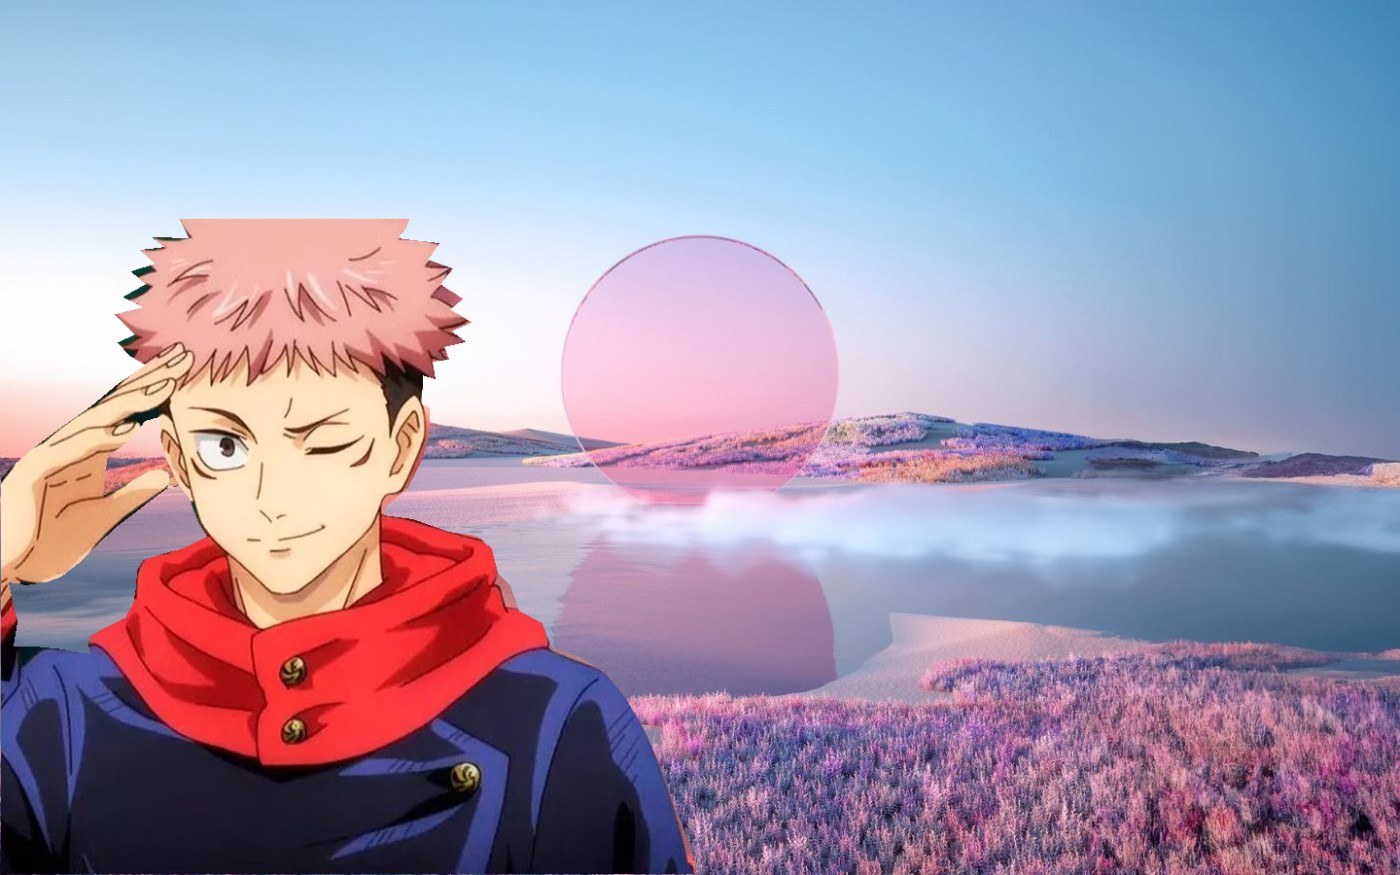

**Feather (alpha)**

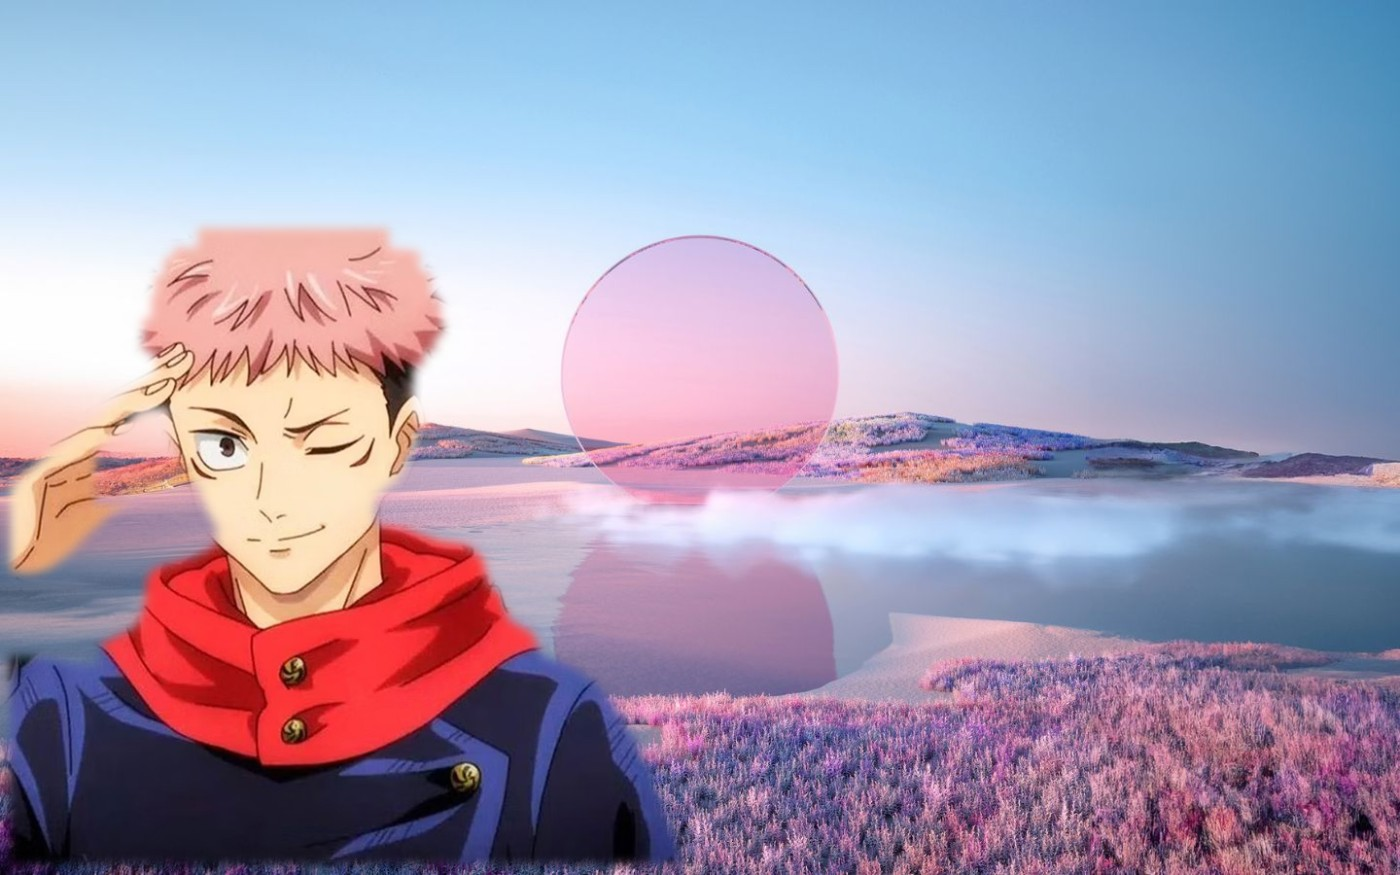

**Laplacian pyramid**

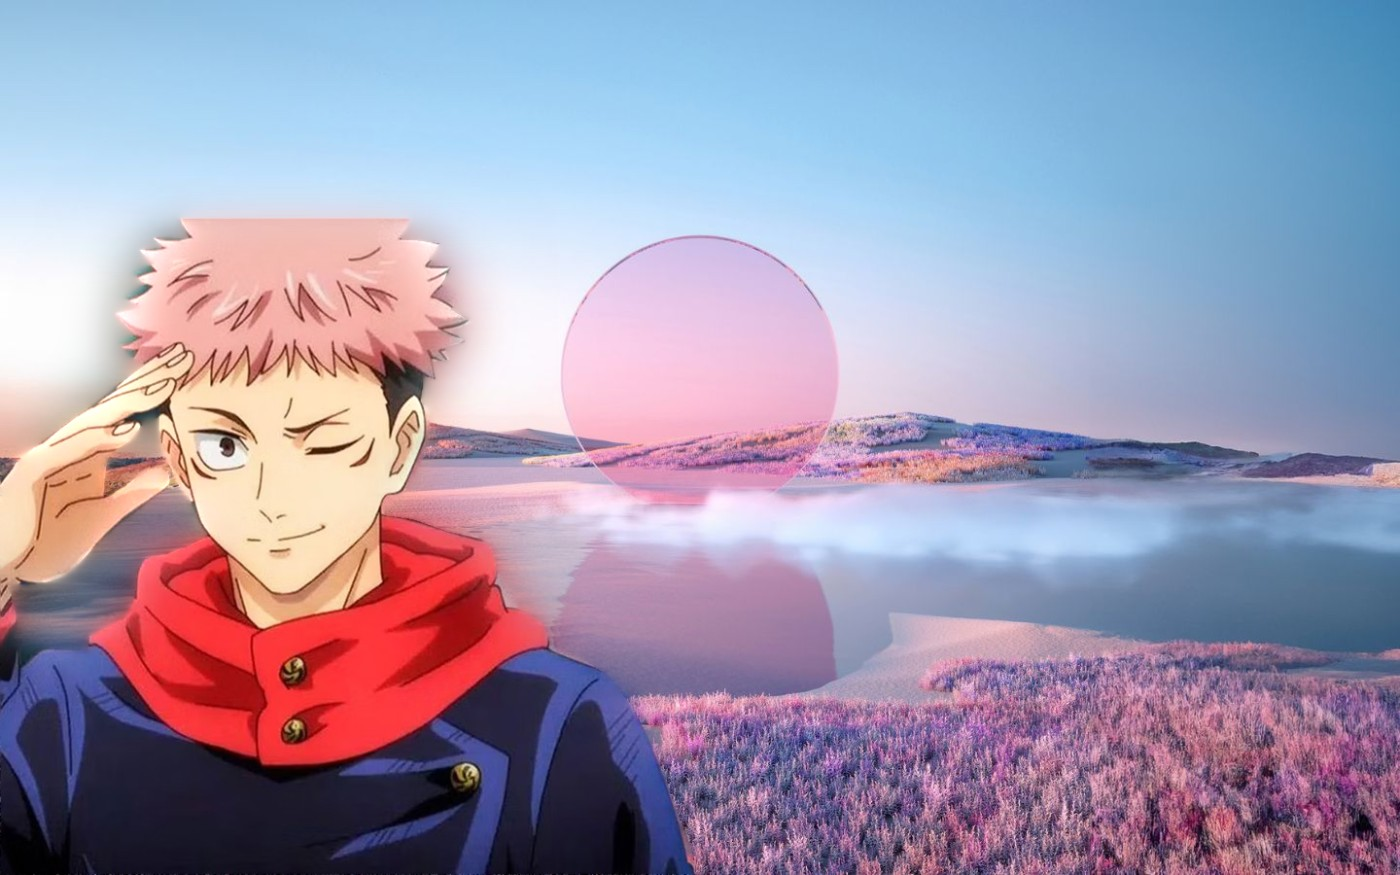

**Poisson import**

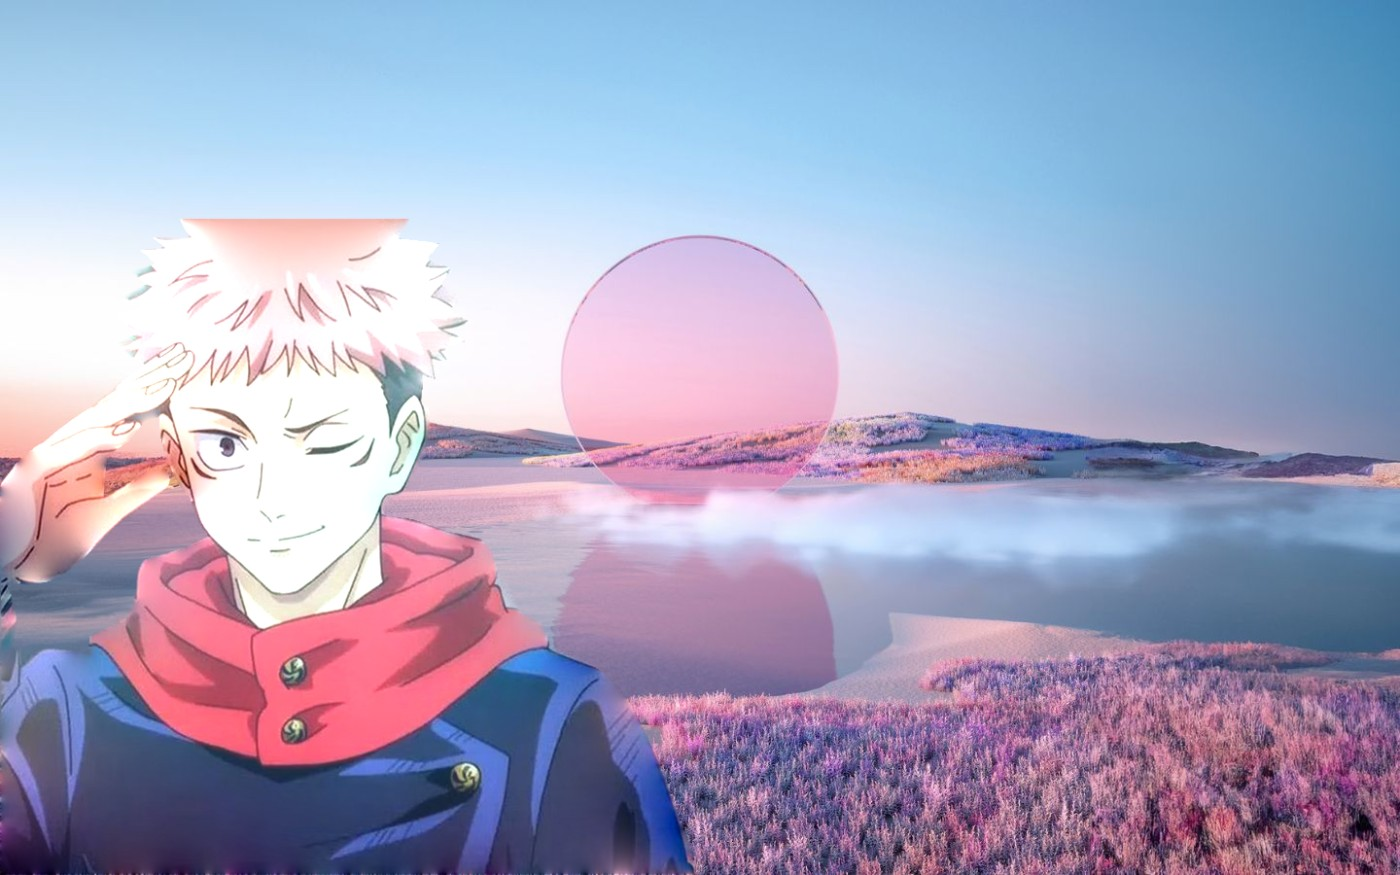

In [5]:
def blend_all(target, src, msk):
    """Chạy tất cả phương pháp ghép."""
    return {
        "1_direct": ("Direct paste", direct_paste(target, src, msk)),
        "2_feather": ("Feather (alpha)", feather_blend(target, src, msk)),
        "3_pyramid": ("Laplacian pyramid", pyramid_blend(target, src, msk)),
        "4_poisson_import": ("Poisson import", poisson_blend(target, src, msk)),
    }


results = blend_all(target, src, msk)
for label, image in results.values():
    show_image(label, image)

**Lưới so sánh các phương pháp**

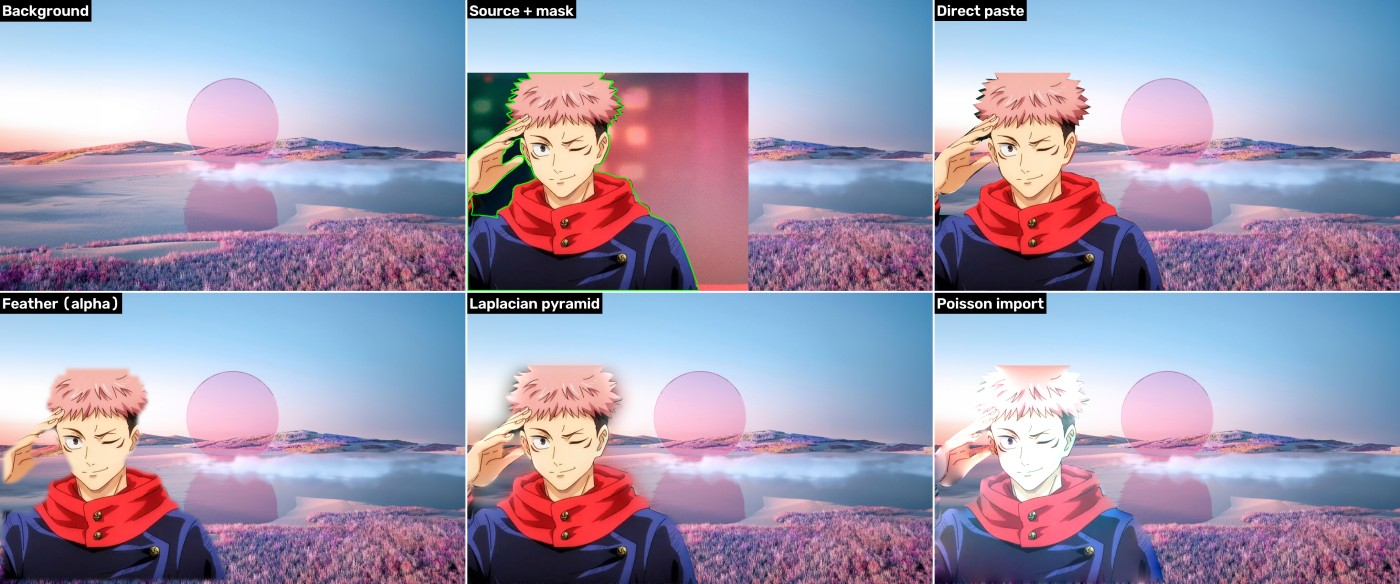

In [6]:
tiles = [labeled(target, "Background"), labeled(placed_view, "Source + mask")]
tiles += [labeled(image, label) for label, image in results.values()]
comparison = make_grid(tiles, cols=3)
show_image("Lưới so sánh các phương pháp", comparison)

## 6. Phóng to vùng biên

Khác biệt giữa các phương pháp nằm chủ yếu ở biên vùng ghép nên ảnh tổng thể khó nhận ra. `zoom_box` chọn một khung vuông nhỏ quanh biên phải của mask, ở khoảng 68% chiều cao hộp bao; cùng khung này được cắt từ cả bốn kết quả và phóng to bằng `INTER_NEAREST` để thấy rõ từng pixel.

**Phóng to vùng biên: x 524–693, y 599–768**

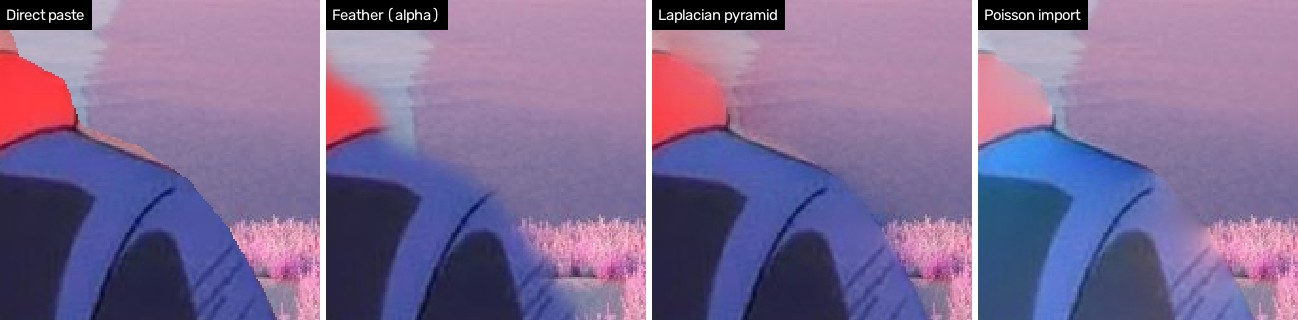

In [7]:
def zoom_box(msk):
    """Chọn khung phóng to quanh biên vùng ghép."""
    x, y, w, h = cv2.boundingRect(msk)
    cy = y + round(0.68 * (h - 1))
    row = np.flatnonzero(msk[cy])
    cx = int(row[-1]) if row.size else x + w // 2
    pad = max(16, min(w, h) // 8)
    x0, y0 = max(cx - pad, 0), max(cy - pad, 0)
    x1, y1 = min(cx + pad + 1, msk.shape[1]), min(cy + pad + 1, msk.shape[0])
    return x0, y0, x1, y1


x0, y0, x1, y1 = zoom_box(msk)
zoom_size = (round(320 * (x1 - x0) / (y1 - y0)), 320)
zooms = [labeled(cv2.resize(image[y0:y1, x0:x1], zoom_size, interpolation=cv2.INTER_NEAREST), label)
         for label, image in results.values()]
zoom = make_grid(zooms, cols=len(zooms))
show_image(f"Phóng to vùng biên: x {x0}–{x1}, y {y0}–{y1}", zoom)

### Nhận xét từ kết quả thực nghiệm

Với cặp ảnh mẫu (nền hoàng hôn sáng, nhân vật có nền xanh tối/đỏ trong ảnh nguồn), quan sát trực tiếp trên ảnh toàn cảnh và vùng phóng to:

- **Direct paste:** giữ nguyên màu và độ sáng của nguồn, nét tóc, tay, áo sắc; nhưng đường bao cứng, nhân vật trông như dán lên nền; còn viền mảnh nâu nhạt ở vai/khăn và vài mảng tối nhỏ của nền nguồn ở mép tóc bên trái.
- **Feather:** biên mềm, không còn đường cắt cứng, nhưng chi tiết mảnh bị nhòe (tóc, ngón tay mờ, bàn tay như bán trong suốt) và có dải nhiễu của nền dọc mép dưới khung; màu nguồn không được chỉnh.
- **Laplacian pyramid:** chi tiết bên trong nhân vật vẫn sắc, chuyển tiếp ở biên mềm hơn direct paste; nhưng có quầng sáng và vùng mờ quanh tóc và tay, lan ra ngoài đường bao mask.
- **Poisson blending:** biên hòa liền vào nền, không còn đường cắt, nét viền, tóc, mắt vẫn thấy rõ; nhưng màu thay đổi mạnh: mặt, tóc và bàn tay rất nhạt, gần trắng; khăn đỏ chuyển sang hồng nhạt; vùng áo gần vai chuyển sang xanh lam sáng; phần áo tối ở mép dưới khung bị nhạt đi và thấy vệt hồng. Hàm mục tiêu chỉ ràng buộc gradient của nguồn và giá trị nền tại biên, không có ràng buộc giữ màu tuyệt đối của nguồn; nền ngay ngoài mask ở đây là bầu trời và mặt nước sáng nên màu bên trong bị kéo theo.

Biên liền mạch chưa đồng nghĩa với ảnh tự nhiên hơn: trên cặp ảnh này Poisson blending giấu được đường nối nhưng chưa giữ được màu của nhân vật.

**Giới hạn:** chỉ một cặp ảnh và là trường hợp khó (nguồn tối, nền sáng); đánh giá hoàn toàn bằng quan sát. Chất lượng phụ thuộc mạnh vào mask và độ chênh màu giữa hai ảnh. Đỉnh đầu nhân vật bị cắt phẳng vì mask chạm mép trên ảnh nguồn; mọi phương pháp đều thừa hưởng điều này. Poisson coi mọi pixel trong mask là ẩn, nên mask lớn làm hệ phương trình lớn hơn. Nhận xét trên áp dụng cho bộ ảnh mẫu, cần kiểm tra lại bằng mắt khi đổi ảnh.